In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

from _path import NB_DIR
import sys
import os
from datetime import datetime
import pickle
import dill
import random
from typing import Optional

sys.path.append(str(NB_DIR))

import torch

from botorch.optim import optimize_acqf
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.acquisition.monte_carlo import qExpectedImprovement
from botorch.acquisition.objective import ConstrainedMCObjective
from botorch.models import ModelListGP, SingleTaskGP
from botorch import fit_gpytorch_mll
from gpytorch.mlls.sum_marginal_log_likelihood import SumMarginalLogLikelihood

from matal.utils import load_cache
from matal.configs import DATA_DIR
from matal.utils.datatype import to_torch
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from matal.recipe import UniformCompositionGenerator, get_rand_comp
from matal.utils import auto_log, get_sid, obj_to_hash, merge_update, Bunch, cache_return, load_cache, save_cache
from matal.configs import BATCH_DIR, PROJ_CODE, MODEL_DIR, DATA_DIR
from matal.robot.ot2 import OT2ProcGeneratorV7

try:
    from sklearn.utils._testing import ignore_warnings
except ImportError:
    from sklearn.utils.testing import ignore_warnings

INFO:numexpr.utils:NumExpr defaulting to 8 threads.


## 0. Load SVM models

In [2]:
svm_models = load_cache('svm_models_v8')
display(svm_models)

X_COLS = ['cons_ZnCl2', 'cons_ZnOTF2', 'ratio_MeOH']
X_LIMS = np.array([35.0, 6.0, 1])

from matal.vis import marching_cubes, skimg_tri_to_poly, poly_to_skimg_tri, smooth_pvs_poly, get_mesh_pred

margin = 0.05
n_points = 331
pred_sol, grid_space, flattened = get_mesh_pred(svm_models['solubility'], margin=margin, n_points=n_points, target='pred')
pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=margin, n_points=n_points, target='pred', margin_value=-5.0)
pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=margin, n_points=n_points, target='pred', margin_value= 5.0)

# Value cutoff 
oer_cutoff = 1.74
her_cutoff = -0.86

merge_pred = ((pred_sol >= 0.5) & (pred_oer >= oer_cutoff) & (pred_her >= her_cutoff)).astype(np.float16)
verts, faces, *_ = marching_cubes(merge_pred, 0.5, spacing=(grid_space, ) * 3, gradient_direction='ascent', allow_degenerate=False)
verts -= margin

# Smooth iso-plane
poly = skimg_tri_to_poly(verts, faces)
smooth_poly = smooth_pvs_poly(poly, sm_iters=500, sm_rlx=0.2, sm2_iters=50, sm2_rlx=0.05, dp_factor=0.95, dp_angle=120, dp_iters=100)
smooth_verts, smooth_faces = poly_to_skimg_tri(smooth_poly)
print(f'Num of edge points:', len(smooth_verts))

# Precalculated kDTree for fast distance computation
import scipy
kdtree = scipy.spatial.KDTree(smooth_verts)

## Low res version for plotting GP model output
_n_points = 51
_pred_sol, _, _flattened = get_mesh_pred(svm_models['solubility'], margin=0, n_points=_n_points, target='pred')
_pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=0, n_points=_n_points, target='pred', margin_value=-5.0)
_pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=0, n_points=_n_points, target='pred', margin_value= 5.0)
_mask = (_pred_sol >= 0.5) & (_pred_oer >= oer_cutoff) & (_pred_her >= her_cutoff)
low_res_X = _flattened[_mask.reshape(-1)].astype(np.float64)
del _n_points, _pred_sol, _flattened, _pred_her, _mask
low_res_X

{'solubility': SVC(C=859.5792940061186, gamma=3.4589836312369657, probability=True,
     random_state=0),
 'HER': SVR(C=6.242440709438059, epsilon=0.004211530744928162, gamma=0.6547642454463255),
 'OER': SVR(C=2.8195945113291416, epsilon=7.409655120425588e-05,
     gamma=2.589799492724016)}

Num of edge points: 18273


array([[0.        , 0.36000001, 0.98000002],
       [0.        , 0.36000001, 1.        ],
       [0.        , 0.38      , 0.92000002],
       ...,
       [0.83999997, 0.        , 0.31999999],
       [0.83999997, 0.        , 0.34      ],
       [0.86000001, 0.        , 0.18000001]])

## 1. Train Gaussian Process models for CE and conductivity 

#### Scale CE using a custom ce_log() function to focus on changes >99%

> https://www.desmos.com/calculator/z0so28skga 


In [3]:
# baseline value when CE = 99%. Choose a baseline value = 2 to make the function always positive within [0, 100)
CE_LOG_BASELINE = 2

def ce_log(x):
    return CE_LOG_BASELINE - np.log10(100 - x)

def inv_ce_log(x):
    return 100 - np.power(10, CE_LOG_BASELINE - x)

_x = np.linspace(0, 100, num=1000000, endpoint=False)
assert np.allclose(_x, inv_ce_log(ce_log(_x)))
del _x

In [4]:
def get_date():
    data_df = pd.read_excel(DATA_DIR / 'Round 1.xlsx')
    CE_COLS = ['CE-1(%)', 'CE-2(%)', 'CE-3(%)']
    TOPTWO_CE_COLS = ['CE-T1(%)', 'CE-T2(%)', ]
    LOG_TOPTWO_CE_COLS = ['LgCE-T1(-)', 'LgCE-T2(-)', ]

    data_df[TOPTWO_CE_COLS] = data_df[CE_COLS].fillna(0).apply(lambda x: np.sort(x)[::-1][:2], axis=1,
                                                               result_type='expand')
    data_df[LOG_TOPTWO_CE_COLS] = ce_log(data_df[TOPTWO_CE_COLS])

    data_df['LgCE_Mean'] = data_df[LOG_TOPTWO_CE_COLS].mean(axis=1)
    data_df['LgCE_Var'] = data_df[LOG_TOPTWO_CE_COLS].var(axis=1, ddof=0)
    data_df['Conductivity_Mean'] = data_df['Conductivity(mS/cm)']
    data_df['Conductivity_Var'] = 1e-4

    lce_scaler = StandardScaler().fit(data_df[['LgCE_Mean']])
    con_scaler = StandardScaler().fit(data_df[['Conductivity_Mean']])

    data_df[['Scaled_LgCE_Mean']] = lce_scaler.transform(data_df[['LgCE_Mean']])
    data_df[['Scaled_LgCE_Var']] = data_df[['LgCE_Var']] / lce_scaler.scale_
    data_df[['Scaled_Conductivity_Mean']] = con_scaler.transform(data_df[['Conductivity_Mean']])
    data_df[['Scaled_Conductivity_Var']] = data_df[['Conductivity_Var']] / con_scaler.scale_

    cond_cutoff = con_scaler.transform([[10]])[0, 0]
    return data_df, lce_scaler, con_scaler, cond_cutoff


def set_seed(seed):
    torch.manual_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.use_deterministic_algorithms(True)


def build_model(data_df, random_seed=None):
    set_seed(random_seed)

    X_COLS = ['cons_ZnCl2(m)', 'cons_ZnOTF2(m)', 'ratio_MeOH(wt%)']
    X_LIMS = np.array([35.0, 6.0, 1.0])
    train_x = to_torch(data_df[X_COLS] / X_LIMS)
    model_lce = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_LgCE_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_LgCE_Var']]),
    )

    model_con = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_Conductivity_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_Conductivity_Var']]),
    ).to(train_x)
    model = ModelListGP(model_lce, model_con)
    mll = SumMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll, max_retries=50, )

    return model, mll


data_df, lce_scaler, con_scaler, cond_cutoff = get_date()
print('Scaled conductivity cutoff =', cond_cutoff)

RANDOM_SEED = 0
model, mll = build_model(data_df, random_seed=RANDOM_SEED)


/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/sklearn/base.py:464: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.6259e-18], dtype=torch.float64), std = tensor([1.0445], dtype=torch.float64)). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


Scaled conductivity cutoff = -0.8907442085975525


/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.5511e-17], dtype=torch.float64), std = tensor([1.0445], dtype=torch.float64)). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/gpytorch/likelihoods/gaussian_likelihood.py:300: GPInputWarning: You have passed data through a FixedNoiseGaussianLikelihood that did not match the size of the fixed noise, *and* you did not specify noise. This is treated as a no-op.
  warnings.warn(


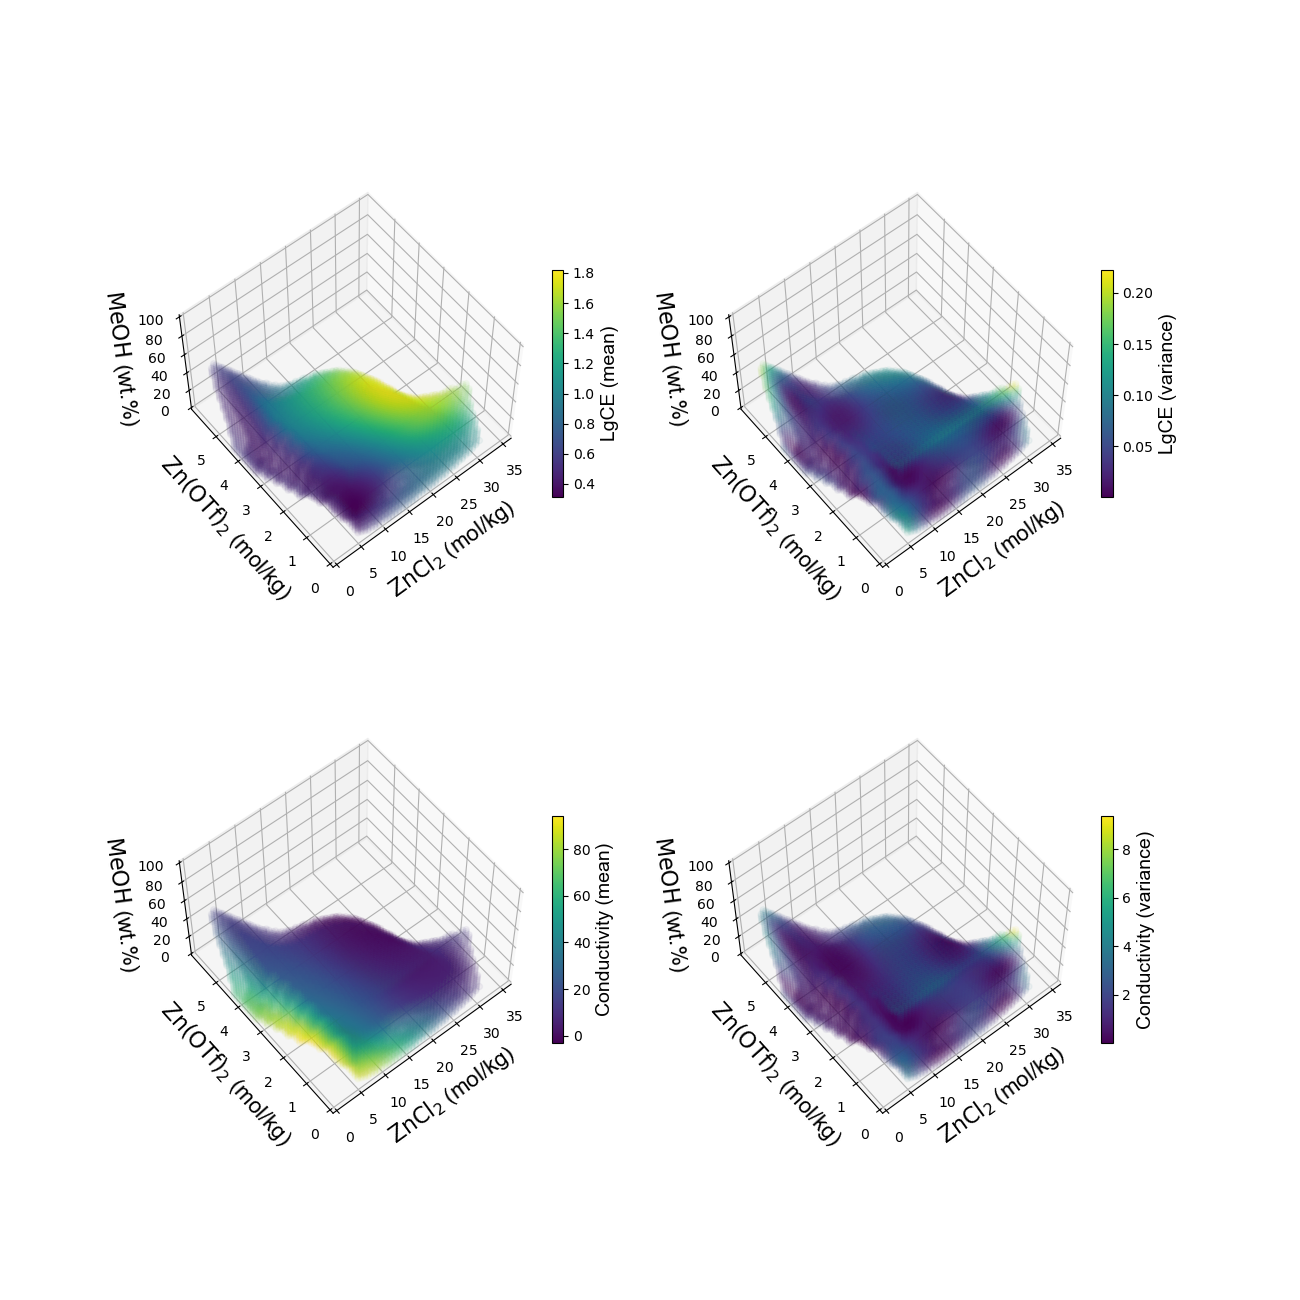

In [5]:
import matplotlib.cm as cm

mpl.rcParams['mathtext.default'] = 'rm'

f_preds = model(to_torch(low_res_X), to_torch(low_res_X))
y_preds = model.likelihood(*f_preds)

X_LIMS_PLT = np.array([35.0, 6.0, 100])

plt.close('all')
fig, axs = plt.subplots(2, 2, subplot_kw=dict(projection='3d'), figsize=(13, 13))

for axr, slice_i, ylabel, scaler in [
    (axs[0], 0, 'LgCE',         lce_scaler),
    (axs[1], 1, 'Conductivity', con_scaler),
]:
    for ax, val_type in [(axr[0], 'mean'), (axr[1], 'variance'), ]:
        vals = getattr(y_preds[slice_i], val_type).detach().numpy()
        if val_type == 'mean':
            vals = scaler.inverse_transform(vals.reshape(-1, 1)).reshape(-1)
        elif val_type == 'variance':
            vals = vals * scaler.scale_[0]
        sc = ax.scatter(*(low_res_X *  X_LIMS_PLT).T, c=vals, alpha=0.05,vmin=vals.min(), vmax=vals.max())
        cbar = plt.colorbar(sc, ax=ax,label=f'{ylabel} ({val_type})', shrink=0.5, pad=0.05)
        cbar.set_label(f'{ylabel} ({val_type})',rotation=90,family='Arial',fontsize=14,x=1)
        cbar.solids.set(alpha=1)
        
        [getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS)]
        [getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_LIMS_PLT)]
     
        ax.set_xlabel('$ZnCl_2$ (mol/kg)',family='Arial',fontsize=16)
        ax.set_ylabel('$Zn(OTf)_2$ (mol/kg)',family='Arial',fontsize=16)
        ax.set_zlabel('$MeOH$ (wt.%)',family='Arial',fontsize=16)


        ax.set_xlim([0,36])
        ax.set_ylim([0,6])
        ax.set_zlim([0, 100])

        ax.xaxis.set_ticks(np.arange(0,36,5))
        ax.yaxis.set_ticks(np.arange(0,6,1))

        ax.xaxis.labelpad = 6
        ax.yaxis.labelpad = 6
        ax.zaxis.labelpad = 6

        ax.view_init(58, -129)
        #ax.set_title(f'{ylabel} - {val_type}')
        


        


## 2. Define acquisition functions constrained by conductivity

In [6]:
dtype = torch.double

def get_aqcf(model, data_df, cond_cutoff, constraint='high_conductivity', mc_sample=1024, seed=None):
    set_seed(seed)
    qmc_sampler = SobolQMCNormalSampler(sample_shape=torch.Size([mc_sample]))
    
    def obj_callable(Z: torch.Tensor, X: Optional[torch.Tensor] = None):
        return Z[..., 0]
    
    if constraint == 'high_conductivity':
        def constraint_callable(Z):
            return  Z[..., 1] - cond_cutoff
        current_f = to_torch(data_df[['Scaled_LgCE_Mean']]) * (to_torch(data_df[['Scaled_Conductivity_Mean']]) >= cond_cutoff)
        
    elif constraint == 'low_conductivity':
        def constraint_callable(Z):
            return  cond_cutoff - Z[..., 1]
        current_f = to_torch(data_df[['Scaled_LgCE_Mean']]) * (to_torch(data_df[['Scaled_Conductivity_Mean']]) < cond_cutoff)
        
    else:
        raise ValueError(f'Unknown aqcf constraint: {constraint}')
    
    constrained_obj = ConstrainedMCObjective(
        objective=obj_callable,
        constraints=[constraint_callable],
    )

    qEI = qExpectedImprovement(
        model=model,
        best_f=current_f.max(),
        sampler=qmc_sampler,
        objective=constrained_obj,
    )
    
    return qEI

hi_qEI = get_aqcf(model, data_df, cond_cutoff, constraint='high_conductivity', seed=RANDOM_SEED)
lo_qEI = get_aqcf(model, data_df, cond_cutoff, constraint='low_conductivity', seed=RANDOM_SEED)

## 3. Generate initial conditions for Bayesian Optimization

*While BoTorch automatically generates initial conditions (i.c.) by default, we have an additional hard nonlinear constraint related to solubility. This constraint is already known and must be satisfied. Therefore, we need to generate those initial conditions ourselves.*

In [7]:
BATCH_SIZE = 6 # Number of samples in each batch. Total sample size is 12, 
               # but half is for high_conductivity and another half for low_conductivity.
               # So the batch size for Bayesian Optimization is 6.

N_RESTARTS = 256 # The number of starting points for multistart acquisition function optimization.
                 # The optimizer will try to maximize the acquisition function N_RESTARTS times
                 # (each time from a different i.c.) and select the best batch.

In [8]:
# Generate multiple batches of i.c. by varying random seed
min_edge_dist = 0.01
min_comp = 0.05

ic_dfs = []
for random_seed in range(N_RESTARTS):
    g = UniformCompositionGenerator(
        cols=X_COLS,
        n_comps=BATCH_SIZE,
        n_iters=BATCH_SIZE * (random_seed % 8) + 1,
        random_state=random_seed,
        dist_col_scales=1 / X_LIMS,
        comp_gen_func=get_rand_comp,
        func_kw=dict(kdtree=kdtree, min_dist=min_edge_dist, min_comp=min_comp, svm_models=svm_models)
    )
    ic_dfs.append(g.optimize())

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/19 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/31 [00:00<?, ?it/s]

... (246 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/31 [00:00<?, ?it/s]

  0%|          | 0/37 [00:00<?, ?it/s]

  0%|          | 0/43 [00:00<?, ?it/s]

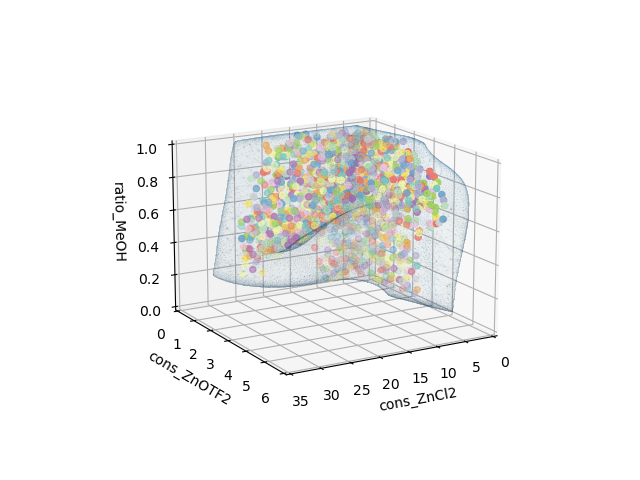

In [9]:
# Visualize those i.c.
plt.close('all')
fig, ax = plt.subplots(1, 1, subplot_kw=dict(projection='3d'))

colors = plt.get_cmap('Set3').colors

ax.plot_trisurf(*(smooth_verts * X_LIMS).T, triangles=smooth_faces, linewidth=0, 
                antialiased=False, alpha=0.02, color='tab:blue', label='HER-OER Model')

for i, ic_df in enumerate(ic_dfs):
    ax.scatter(*ic_df[X_COLS].values.T, color=colors[i % len(colors)])

[getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS)]
[getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_LIMS)]
ax.view_init(15, 60)

## 4. Run Bayesian Optimization with solubility constraint


In [10]:
@ignore_warnings(category=UserWarning)
def solubility_constraint(X: torch.Tensor):
    input = X.detach().numpy()
    sol = svm_models['solubility'].predict(input)
    her = svm_models['HER'].predict(input)
    oer = svm_models['OER'].predict(input)
    out = (sol > 0.5) & (her > her_cutoff) & (oer > oer_cutoff)
    out = out.astype(np.float64)
    out = out * 2 - 1
    return to_torch(out.min())

# Convert i.c. into pytorch tensor
all_ic_df = pd.concat(ic_dfs, ignore_index=True)
batch_initial_conditions = to_torch(all_ic_df.values / X_LIMS).reshape(N_RESTARTS, BATCH_SIZE, 3).contiguous()
bounds = torch.tensor([[0.0] * 3, [1.0] * 3], dtype=dtype)


# # Set logger level to INFO so we can monitor progress during optimize_acqf()
# from botorch.logging import logger as botorch_logger
# botorch_logger.setLevel('INFO')

In [11]:
@ignore_warnings(category=RuntimeWarning)
def find_candidates(acq_function, batch_initial_conditions):
    # The optimize_acqf() function in BoTorch requires that callable provided in nonlinear_inequality_constraints be differentiable. 
    # However, our constraint is evaluated using sklearn’s SVM models, which are not supported by PyTorch’s automatic differentiation engine. 
    # For a quick bypass, we patch related functions in BoTorch to drop gradient calculation.
    import botorch
    assert botorch.__version__ == '0.11.0'         # Check botorch version since we are modifying private functions
    from matal.utils.patch import patch_botorch_nonlinear_constraints_no_grad
    patch_botorch_nonlinear_constraints_no_grad()  # Apply patch

    set_seed(RANDOM_SEED)
    candidates, acqf_vals = optimize_acqf(
        acq_function=acq_function,
        bounds=bounds,
        q=BATCH_SIZE,
        num_restarts=N_RESTARTS,
        options={'with_grad': False},        # Disable gradiant calculation
        nonlinear_inequality_constraints=[
            (solubility_constraint, False),  # True for intra-point constraint, False for inter-point constraint
                                             # The solubility constraint is an intra-point constraint, meaning that 
                                             # each composition is independent. However, for performance reasons, we 
                                             # run them in inter-point mode.
        ],
        batch_initial_conditions=batch_initial_conditions,
    )
    return candidates.detach().numpy(), acqf_vals.detach().numpy()

jobs = []
for i in range(N_RESTARTS):
    for tag, acqf in [('hi', hi_qEI), ('lo', lo_qEI), ]:
        jobs.append((tag, acqf, batch_initial_conditions[i:i+1,:,:].contiguous()))

from joblib import Parallel, delayed
results = Parallel(n_jobs=8, backend='loky', verbose=20)(delayed(find_candidates)(acqf, ic) for _, acqf, ic in jobs)


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   1 tasks      | elapsed:   12.1s
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:   30.1s
[Parallel(n_jobs=8)]: Done   3 tasks      | elapsed:  1.9min
[Parallel(n_jobs=8)]: Done   4 tasks      | elapsed:  1.9min
[Parallel(n_jobs=8)]: Done   5 tasks      | elapsed:  1.9min
[Parallel(n_jobs=8)]: Done   6 tasks      | elapsed:  1.9min
[Parallel(n_jobs=8)]: Done   7 tasks      | elapsed:  2.9min
[Parallel(n_jobs=8)]: Done   8 tasks      | elapsed:  3.1min
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:  3.1min
[Parallel(n_jobs=8)]: Done  10 tasks      | elapsed:  4.1min
[Parallel(n_jobs=8)]: Done  11 tasks      | elapsed:  4.1min
[Parallel(n_jobs=8)]: Done  12 tasks      | elapsed:  4.9min
[Parallel(n_jobs=8)]: Done  13 tasks      | elapsed:  5.2min
[Parallel(n_jobs=8)]: Done  14 tasks      | elapsed:  5.3min
[Parallel(n_jobs=8)]: Done  15 tasks      | elapsed:  5.4min
[Parallel(

In [12]:
rows = []
for i, ((tag, _, _), (candidates, acqf_vals)) in enumerate(zip(jobs, results)):
    rows.append(dict(Idx=i, Tag=tag, acqf_val=acqf_vals.tolist()))
result_df = pd.DataFrame(rows)
result_df

,Idx,Tag,acqf_val
0,0,hi,1.131688
1,1,lo,0.002128
2,2,hi,0.498551
3,3,lo,0.000429
4,4,hi,1.106607
...,...,...,...
507,507,lo,0.000000
508,508,hi,1.086177
509,509,lo,0.006025
510,510,hi,0.548396


In [13]:
# save_cache(results, 'batch_AL_02.results')
# save_cache(jobs, 'batch_AL_02.jobs')
# save_cache(result_df, 'batch_AL_02.result_df')

# results = load_cache('batch_AL_02.results')
# jobs = load_cache('batch_AL_02.jobs')
# result_df = load_cache('batch_AL_02.result_df')


In [14]:
best_hi_idx = result_df[result_df.Tag == 'hi'].sort_values('acqf_val').Idx.values[-1]
best_lo_idx = result_df[result_df.Tag == 'lo'].sort_values('acqf_val').Idx.values[-1]

hi_candidates = results[best_hi_idx][0]
lo_candidates = results[best_lo_idx][0]


In [15]:
def gen_pred_df(candidates):
    X = to_torch(candidates)
    f_preds = model(X, X)
    y_preds = model.likelihood(*f_preds)
    df = pd.DataFrame(candidates * X_LIMS, columns=X_COLS)
    df['Pred_LgCE'] = lce_scaler.inverse_transform(y_preds[0].mean.detach().numpy().reshape(-1, 1)).reshape(-1)
    df['Pred_CE'] = inv_ce_log(df['Pred_LgCE'].values)
    df['Pred_LgCE_Var'] = lce_scaler.scale_[0] * y_preds[0].variance.detach().numpy()
    df['Pred_Conductivity'] = con_scaler.inverse_transform(y_preds[1].mean.detach().numpy().reshape(-1, 1)).reshape(-1)
    df['Pred_Conductivity_Var'] = con_scaler.scale_[0] * y_preds[1].variance.detach().numpy()
    return df

hi_df = gen_pred_df(hi_candidates)
hi_df['Tag'] = 'Hign_Cond'
lo_df = gen_pred_df(lo_candidates)
lo_df['Tag'] = 'Low_Cond'

batch_df = pd.concat([hi_df, lo_df], ignore_index=True)
batch_df

/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/gpytorch/likelihoods/gaussian_likelihood.py:300: GPInputWarning: You have passed data through a FixedNoiseGaussianLikelihood that did not match the size of the fixed noise, *and* you did not specify noise. This is treated as a no-op.
  warnings.warn(
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/gpytorch/likelihoods/gaussian_likelihood.py:300: GPInputWarning: You have passed data through a FixedNoiseGaussianLikelihood that did not match the size of the fixed noise, *and* you did not specify noise. This is treated as a no-op.
  warnings.warn(


,cons_ZnCl2,cons_ZnOTF2,ratio_MeOH,Pred_LgCE,Pred_CE,Pred_LgCE_Var,Pred_Conductivity,Pred_Conductivity_Var,Tag
0,16.587997,1.534952,0.906095,1.817390,98.477316,0.049635,0.606288,0.792873,Hign_Cond
1,17.220460,0.460461,0.601537,1.236159,94.194487,0.044055,6.647133,1.541619,Hign_Cond
2,7.678242,2.268793,0.705347,1.073108,91.549320,0.021008,11.603395,0.646707,Hign_Cond
3,19.108975,0.523022,0.321817,0.994624,89.875443,0.068217,20.426553,2.439273,Hign_Cond
4,17.906756,1.531262,0.789270,1.738329,98.173282,0.057313,-1.440282,1.304452,Hign_Cond
5,1.929974,2.720002,0.909999,0.990947,89.789358,0.029623,16.421547,0.425261,Hign_Cond
6,2.736839,1.428739,0.717207,0.745130,82.016663,0.048602,31.471039,1.242221,Low_Cond
7,8.869411,1.975674,0.827564,1.324296,95.260808,0.040201,6.727553,1.371848,Low_Cond
8,2.032358,3.519750,0.851728,0.765344,82.834529,0.027938,12.796778,0.856307,Low_Cond
9,21.958865,0.179648,1.000000,1.663647,97.830534,0.145811,9.977253,5.135426,Low_Cond


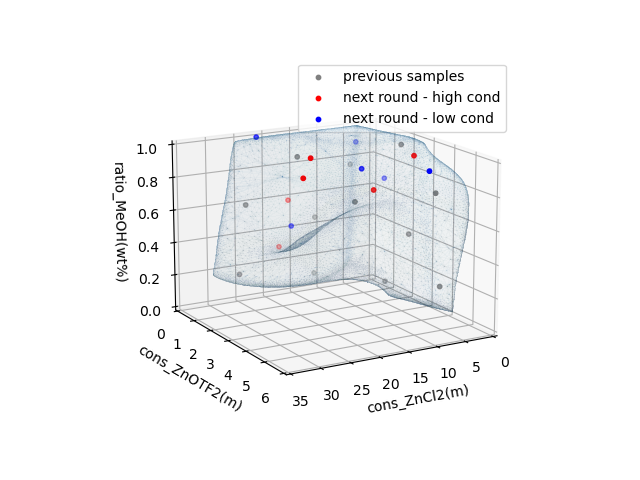

In [16]:
plt.close('all')
fig, ax = plt.subplots(1, 1, subplot_kw=dict(projection='3d'))
ax.plot_trisurf(*(smooth_verts * X_LIMS).T, triangles=smooth_faces, linewidth=0, 
                antialiased=False, alpha=0.02, color='tab:blue')

X_COLS = ['cons_ZnCl2(m)', 'cons_ZnOTF2(m)', 'ratio_MeOH(wt%)']
ax.scatter(*data_df[X_COLS].values.T, s=10, color='grey', label='previous samples')
ax.scatter(*(hi_candidates * X_LIMS).T, s=10, color='red', label='next round - high cond')
ax.scatter(*(lo_candidates * X_LIMS).T, s=10, color='blue', label='next round - low cond')

[getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS)]
[getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_LIMS)]
ax.view_init(15, 60)
ax.legend()

In [18]:
batch_num = 2
batch_sid = get_sid('Batch', i=batch_num, usage='active_learning')
batch_sid

'aEB-0200'